# 03 — Put each dataset on H3

Each dataset is gridded once, at the H3 resolution `02_fit_resolution` fitted to it, with covering assignment.
Covering shares each pixel over the cells it overlaps by area, so a cell's value is the area-weighted mean of its pixels.
A raster in a projected CRS (Stage IV on the HRAP polar stereographic grid, HLS in UTM) is gridded on its own pixels, so its shares are shares of a source pixel.
`pixel_weight` is the sum of those pixel-area shares (below 1 when the cell is smaller than a pixel), not a pixel count; for a monthly row it is the mean of the daily or weekly weights.
For the coarse datasets a covered cell with no valid pixel (outside the AOI outline, or masked) gets a NULL measure and a `pixel_weight` of 0; for HLS only cells with a valid (cloud-free) pixel are kept (`GRID_COVERAGE` in `config_nb`).

In [0]:
%run ./config_nb

geobrix 0.6.0: one wheel per runtime (+env5 / +env6); SQL functions register through databricks.labs.gbx.register(spark); the Python API is rasterx / gridx / vectorx. See https://databrickslabs.github.io/geobrix/docs/migration-0-6
geobrix: JVM level unavailable: Spark Connect session (Serverless); using the Python level (48 functions)
geobrix: SQL expression level unavailable: 5 functions (gbx_bng_cellarea, gbx_bng_eastnorthasbng, gbx_quadbin_distance, ...) need a SQL function wrapper, and SQL functions are unavailable here; using the Python level


... EARTHDATA_TOKEN loaded from geospatial_docs.vapor_eyes.earthdata_token


True

DataFrame[]

H3PX_DIR = /Volumes/geospatial_docs/h3_pixels_crop_yield/data/h3-pixels-crop-yield


... view helpers: show_cells, show_tile (gated by INTERACTIVE_PLOTS)


## One gridding pass per dataset

Tiles are clipped to the AOI and cut into sub-tiles of `RETILE_PX` pixels.
The states from the sub-tiles of one date merge by summing `count` and `sum`.

In [0]:
RES = {r["dataset"]: r["attr_h3_res"] for r in spark.table("dataset_resolutions").collect()}


def daily_states(dataset):
    """Per (date, cell): the merged covering state of one dataset at its fitted resolution."""
    res, coverage = RES[dataset], GRID_COVERAGE.get(dataset, "complete")
    tiles = dataset_tiles(dataset)
    rule = tiles.select("band_date_rule").first()["band_date_rule"]
    # One view name per dataset: a DataFrame from spark.sql resolves its views when it runs (Spark Connect), so a
    # shared name would point every dataset's states at the last dataset gridded.
    tiles.createOrReplaceTempView(f"_tiles_{dataset}")
    sub = spark.sql(f"""SELECT s.collect_date, struct(t.*) AS tile
                        FROM _tiles_{dataset} s, LATERAL gbx_rst_retile(s.tile, {RETILE_PX}, {RETILE_PX}) t""")
    parts = (sub.repartition(FANOUT, "collect_date", "tile.window")
             .selectExpr("collect_date", f"gbx_rst_h3_rastertogrid_partial(tile, {res}, '{coverage}', 'covering') AS cells"))
    parts.createOrReplaceTempView(f"_parts_{dataset}")
    # OUTER inline + a NULL filter: a plain inline lets Spark push an inferred size(cells) > 0 filter below the
    # repartition, which runs the gridding twice.
    return spark.sql(f"""
      SELECT {band_to_date_sql(rule, 'c.band')} AS day, c.cellid AS attr_h3_cellid,
             sum(c.count) AS pixel_weight, try_divide(sum(c.sum), sum(c.count)) AS attr_measure
      FROM _parts_{dataset} p LATERAL VIEW OUTER inline(p.cells) c
      WHERE c.cellid IS NOT NULL
      GROUP BY 1, 2""").withColumn("attr_h3_res", F.lit(res))


def monthly(states, dataset, attr_name, how, months, scale=1.0):
    """Daily or weekly cell states to monthly rows of h3_dataset_measures (config_nb monthly_reduce)."""
    m = monthly_reduce(states, "attr_measure", how, months, scale, ["attr_h3_res", "attr_h3_cellid"],
                       extra=[F.avg("pixel_weight").alias("pixel_weight")])
    return m.select(F.lit(dataset).alias("dataset"), "collect_date", F.lit(attr_name).alias("attr_name"),
                    "attr_h3_res", "attr_h3_cellid", F.col("measure").alias("attr_measure"), "pixel_weight")

## Monthly measures per attribute

One row of the `config_nb` attribute table per attribute.
Stage IV daily totals sum to a monthly total.
The normals, gridMET daily wind and the GRACE-DA weeks average into the month their date falls in.

In [0]:
states, by_attr = {}, {}
for key, dataset, attr, how, months, scale in ATTRIBUTES:
    print(f"... {key}: {attr} at res {RES[key]}")
    states[key] = daily_states(key)
    by_attr[(dataset, attr)] = monthly(states[key], dataset, attr, how, months, scale)
parts = list(by_attr.values())

... stage4: precip_mm at res 7
... normals: precip_normal_mm at res 7
... gridmet: wind_speed_ms at res 7
... gws_inst: gws_inst at res 6
... sfsm_inst: sfsm_inst at res 6


A monthly total is only as complete as its days.
For each attribute that sums days into a month, the next cell counts the days with a value per cell and month, and reports any month shorter than the calendar month (cells with no valid pixel on any day are left out).
It reports; it drops nothing.
It grids Stage IV again: Serverless keeps no cache, so each check recomputes its input.

In [0]:
for key, dataset, attr, how, months, scale in ATTRIBUTES:
    if how != "sum":
        continue
    days = (monthly_reduce(states[key], "attr_measure", how, months, scale, ["attr_h3_cellid"])
            .groupBy("collect_date")
            .agg(F.max("n_days").alias("days"), F.sum(F.when((F.col("n_days") > 0) & (F.col("n_days") < F.dayofmonth(
                F.last_day("collect_date"))), 1).otherwise(0)).alias("short_cells"))
            .withColumn("month_days", F.dayofmonth(F.last_day("collect_date"))).orderBy("collect_date").collect())
    print(f"... {dataset}/{attr}: days with a value per month " + ", ".join(f"{r['collect_date']:%Y-%m} {r['days']}/{r['month_days']}" for r in days))
    short = [r for r in days if r["days"] < r["month_days"] or r["short_cells"] > 0]
    for r in short:
        print(f"    SHORT {r['collect_date']:%Y-%m}: at most {r['days']} of {r['month_days']} days, {r['short_cells']:,} cells short")
    print(f"... {dataset}/{attr}: {sum(r['days'] for r in days)} days in {len(days)} months; "
          + ("no short month" if not short else f"{len(short)} short month(s)"))

... stage4/precip_mm: days with a value per month 2023-05 31/31, 2023-06 30/30, 2023-07 31/31, 2023-08 31/31, 2023-09 30/30
... stage4/precip_mm: 153 days in 5 months; no short month


## The precipitation anomaly

The monthly Stage IV total minus the 2006-2020 normal.
It is a key join, because both fit the same resolution.

In [0]:
st4, nrm = by_attr[("stage4", "precip_mm")].alias("s"), by_attr[("normals", "precip_normal_mm")].alias("n")
parts.append(st4.join(nrm, ["collect_date", "attr_h3_res", "attr_h3_cellid"])
             .select(F.lit("precip_anomaly").alias("dataset"), "collect_date", F.lit("precip_anom_mm").alias("attr_name"),
                     "attr_h3_res", "attr_h3_cellid", (F.col("s.attr_measure") - F.col("n.attr_measure")).alias("attr_measure"),
                     F.col("s.pixel_weight").alias("pixel_weight")))

## NDVI per August scene

NDVI with the Fmask cloud bit masked.
Neighbouring MGRS tiles overlap, so a pixel seen in more than one tile enters a cell once per tile: the mean barely moves, and `pixel_weight` grows with the number of overlapping tiles.
Scenes of one date merge into one row per cell.

In [0]:
if EARTHDATA_READY:
    for ds_name in ("hls_l30", "hls_s30"):
        s = daily_states(ds_name)
        parts.append(s.select(F.lit(ds_name).alias("dataset"), F.col("day").alias("collect_date"), F.lit("ndvi").alias("attr_name"),
                              "attr_h3_res", "attr_h3_cellid", "attr_measure", "pixel_weight"))
measures = _persist(functools.reduce(DataFrame.unionByName, parts), "h3_dataset_measures",
                    cluster_by=["dataset", "attr_h3_cellid"])

... wrote table h3_dataset_measures (139,687,580 rows)


## Check the layer

Per dataset and attribute: cells, valid measures, the `pixel_weight` range and NaN count.
The checks: no NaN, a valid measure in every attribute, no negative weight, no NULL measure where a pixel counted, one row per dataset, date, attribute and cell, and monthly precipitation between 0 and 2,000 mm.

In [0]:
chk = spark.sql("""SELECT dataset, attr_name, count(*) AS cells, count(attr_measure) AS valid,
                          min(pixel_weight) AS min_w, max(pixel_weight) AS max_w,
                          sum(CASE WHEN isnan(attr_measure) THEN 1 ELSE 0 END) AS nan
                   FROM h3_dataset_measures GROUP BY 1, 2 ORDER BY 1, 2""")
display(chk)
assert all(r["nan"] == 0 and r["valid"] > 0 and r["min_w"] >= 0 for r in chk.collect())
assert spark.sql("SELECT count(*) c FROM h3_dataset_measures WHERE attr_measure IS NULL AND pixel_weight > 0").first()["c"] == 0
dup = spark.sql("""SELECT count(*) c FROM (SELECT 1 FROM h3_dataset_measures
                   GROUP BY dataset, collect_date, attr_name, attr_h3_cellid HAVING count(*) > 1)""").first()["c"]
assert dup == 0, f"{dup} duplicate (dataset, collect_date, attr_name, attr_h3_cellid) keys"
rng = spark.sql("""SELECT dataset, min(attr_measure) AS mn, max(attr_measure) AS mx FROM h3_dataset_measures
                   WHERE dataset IN ('stage4', 'normals') GROUP BY 1 ORDER BY 1""").collect()
print("... monthly precipitation (mm):", {r["dataset"]: (round(r["mn"], 1), round(r["mx"], 1)) for r in rng})
assert all(0 <= r["mn"] and r["mx"] < 2000 for r in rng), "monthly precipitation outside 0-2000 mm"

dataset,attr_name,cells,valid,min_w,max_w,nan
grace,gws_inst,872,872,2.463243149083581e-05,0.25037353118767225,0
grace,sfsm_inst,1090,1090,2.463243149083581e-05,0.25037353118767225,0
gridmet,wind_speed_ms,5480,5480,0.000564051243349185,0.32167137603875234,0
hls_l30,ndvi,58388384,58388384,4.4117571969659865e-13,0.6725731119793308,0
hls_s30,ndvi,81272529,81272529,2.508066353132166e-13,0.6725731119793308,0
normals,precip_normal_mm,5495,5495,1.4844246640338704e-05,0.32171064615947104,0
precip_anomaly,precip_anom_mm,5495,5460,0.0,0.2810797995649457,0
stage4,precip_mm,8235,5885,0.0,0.2812067621869018,0


... monthly precipitation (mm): {'normals': (93.2, 156.5), 'stage4': (16.7, 206.7)}


## Payoff

The July precipitation anomaly of the first season, on the Stage IV cells over the AOI.
The colour range is symmetric about zero, so white is the normal, blue wetter and red drier.

<Axes: title={'center': 'July 2023 precipitation anomaly (mm), res 7'}>

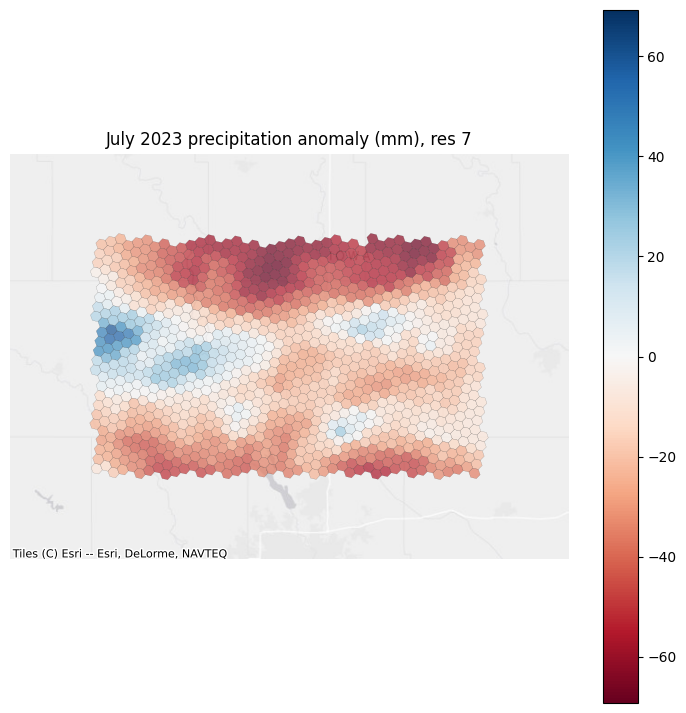

In [0]:
july = f"{SEASONS[0]}-07-01"
anom = spark.table("h3_dataset_measures").where(f"dataset = 'precip_anomaly' AND collect_date = '{july}'")
m = anom.select(F.max(F.abs("attr_measure"))).first()[0]  # the largest |anomaly|: -m to m puts 0 in the middle
show_cells(anom, "attr_h3_cellid", "attr_measure", f"July {SEASONS[0]} precipitation anomaly (mm), res {RES['stage4']}",
           cmap="RdBu", vmin=-m, vmax=m)